### Part A - Image Representation

##### A.1 Read the face images as grayscale pixel matrices, inspect their dimensions and intensity values, flatten each image into a feature vector, and create the complete image matrix with subject labels.

In [40]:
from pathlib import Path
import numpy as np
from PIL import Image

data_root = Path.cwd() / "data"
print("Dataset exists:", data_root.exists())

face_imgs = []
subject_ids = []

for subject_dir in sorted(data_root.iterdir(), key=lambda x: int(x.name[1:])):
    if subject_dir.is_dir() and subject_dir.name.startswith("s"):
        subject_id = int(subject_dir.name[1:])

        for img_path in sorted(subject_dir.iterdir()):
            if img_path.is_file():
                try:
                    pil_img = Image.open(img_path).convert("L")
                    face_imgs.append(np.array(pil_img))
                    subject_ids.append(subject_id)
                except (OSError, ValueError):
                    pass

targets = np.array(subject_ids)

print("Total images:", len(face_imgs))
print("Total subjects:", len(np.unique(targets)))

print("Image dimensions:", face_imgs[0].shape)
print("Pixel data type:", face_imgs[0].dtype)
print("Minimum intensity:", face_imgs[0].min())
print("Maximum intensity:", face_imgs[0].max())
print("First 5x5 pixels:\n", face_imgs[0][:5, :5])

Dataset exists: True
Total images: 400
Total subjects: 40
Image dimensions: (112, 92)
Pixel data type: uint8
Minimum intensity: 11
Maximum intensity: 234
First 5x5 pixels:
 [[48 49 45 47 49]
 [45 52 39 46 56]
 [45 50 42 51 51]
 [49 46 47 47 50]
 [46 46 47 48 48]]


In [41]:
# Convert every 2D image into a 1D vector.
pixel_matrix = np.array([pil_img.flatten() for pil_img in face_imgs]).astype(np.float64)

print("Feature matrix shape:", pixel_matrix.shape)
print("Label array shape:", targets.shape)

# Display the first 10 pixel features of the first image
print("First 10 features:", pixel_matrix[0][:10])

Feature matrix shape: (400, 10304)
Label array shape: (400,)
First 10 features: [48. 49. 45. 47. 49. 57. 39. 42. 53. 49.]


##### A.2 Create a reproducible train-test split with images from every subject represented in both sets.

In [42]:
from sklearn.model_selection import train_test_split

train_pixels, test_pixels, train_targets, test_targets = train_test_split(
    pixel_matrix,
    targets,
    test_size=0.20,
    random_state=42,
    stratify=targets
)

print("Training features:", train_pixels.shape)
print("Testing features:", test_pixels.shape)
print("Training labels:", train_targets.shape)
print("Testing labels:", test_targets.shape)

# Confirm every subject appears in both sets.
print("Training subjects:", len(np.unique(train_targets)))
print("Testing subjects:", len(np.unique(test_targets)))

assert set(np.unique(train_targets)) == set(np.unique(test_targets))
print("All subjects appear in both sets.")

Training features: (320, 10304)
Testing features: (80, 10304)
Training labels: (320,)
Testing labels: (80,)
Training subjects: 40
Testing subjects: 40
All subjects appear in both sets.


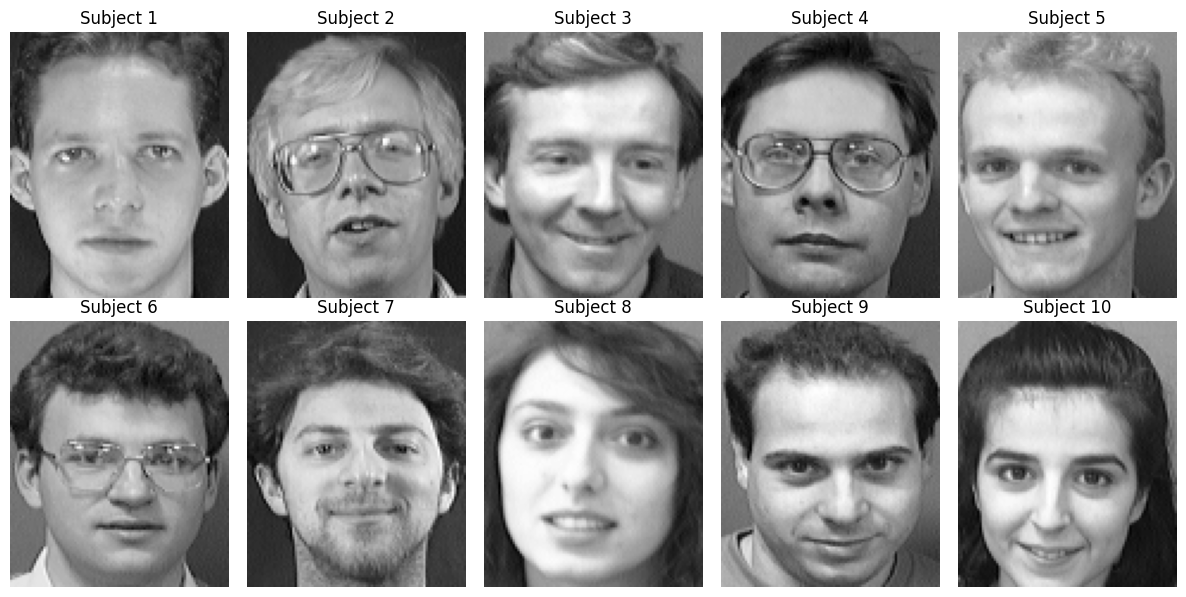

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for idx, subj in enumerate(range(1, 11)):
    img_idx = subject_ids.index(subj)

    plt.subplot(2, 5, idx + 1)
    plt.imshow(face_imgs[img_idx], cmap="gray")
    plt.title(f"Subject {subj}")
    plt.axis("off")

plt.tight_layout()
plt.show()

#### Part B - PCA, Eigenfaces and Compression

##### B.1 Compute the mean face and center the training data. Use covariance/eigendecomposition and SVD to obtain the principal directions and compare the two approaches.

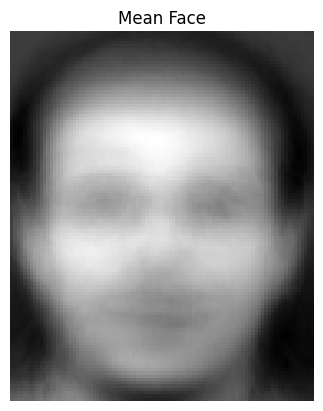

In [44]:
# Mean face - avg of all training images, calculated pixel by pixel coz pca works with variations around mean
avg_face = np.mean(train_pixels, axis=0)

plt.imshow(avg_face.reshape(face_imgs[0].shape), cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

In [45]:
# Center the training data around mean as PCA work on deviations from mean face

train_centered = train_pixels - avg_face

print("Original training shape:", train_pixels.shape)
print("Centered training shape:", train_centered.shape)
print("Mean of centered data:", np.mean(train_centered))

Original training shape: (320, 10304)
Centered training shape: (320, 10304)
Mean of centered data: -3.2382654184097733e-16


In [46]:
# Find the directions in which the faces vary the most, these are called principal components, also called eigenfaces
# Calculate the small covariance matrix
cov_small = train_centered @ train_centered.T

# Find eigenvalues and eigenvectors
eig_vals, eig_vecs = np.linalg.eigh(cov_small)

# Sort from largest eigenvalue to smallest
sort_idx = np.argsort(eig_vals)[::-1]
eig_vals = eig_vals[sort_idx]
eig_vecs = eig_vecs[:, sort_idx]

print("Covariance matrix shape:", cov_small.shape)
print("Eigenvalues shape:", eig_vals.shape)
print("Eigenvectors shape:", eig_vecs.shape)
print("Largest 5 eigenvalues:", eig_vals[:5])

Covariance matrix shape: (320, 320)
Eigenvalues shape: (320,)
Eigenvectors shape: (320, 320)
Largest 5 eigenvalues: [9.06150708e+08 6.62380815e+08 3.53743491e+08 2.89960577e+08
 2.69278582e+08]


Eigenfaces shape: (10304, 320)


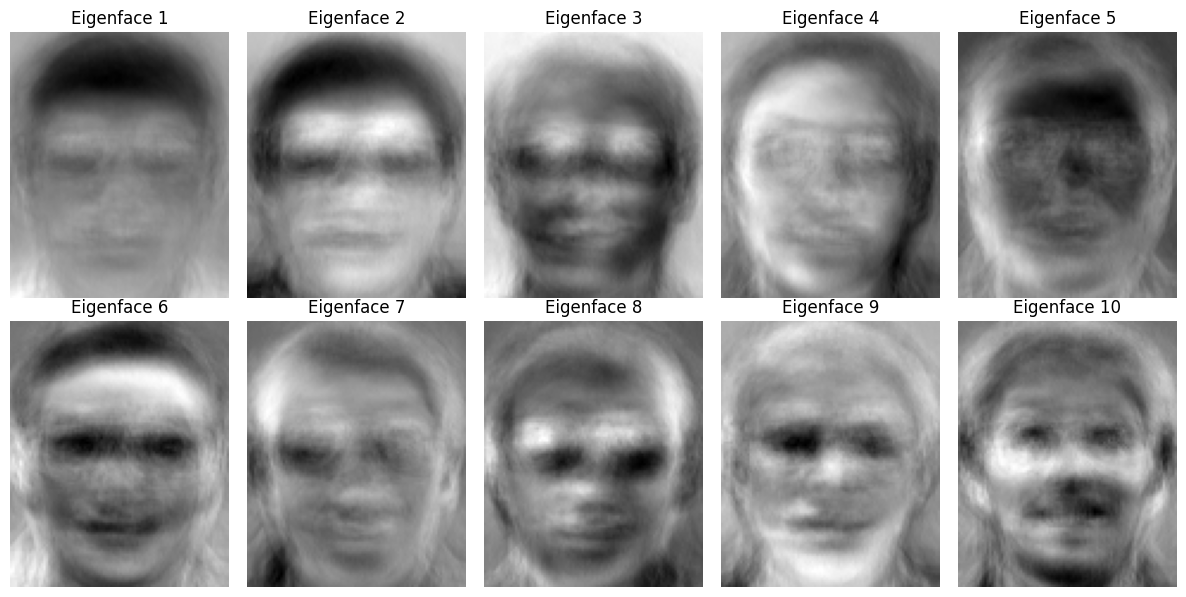

In [47]:
# Calculate the eigenfaces
# Convert small-space eigenvectors into pixel-space directions
eig_faces = train_centered.T @ eig_vecs

# Normalize each eigenface
eig_faces = eig_faces / np.sqrt(np.maximum(eig_vals, 1e-10))

print("Eigenfaces shape:", eig_faces.shape)

# Visualize the first 10 eigenfaces
plt.figure(figsize=(12, 6))

for idx in range(10):
    plt.subplot(2, 5, idx + 1)

    eig_img = eig_faces[:, idx].reshape(face_imgs[0].shape)

    plt.imshow(eig_img, cmap="gray")
    plt.title(f"Eigenface {idx + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [48]:
# Checking for orthogonality in first two eigenfaces
print("First eigenface norm:", np.linalg.norm(eig_faces[:, 0]))
print("Dot product of first two:",
      np.dot(eig_faces[:, 0], eig_faces[:, 1]))

First eigenface norm: 1.0000000000000002
Dot product of first two: -3.469446951953614e-18


##### B.2 Plot cumulative explained variance and retain the minimum number of components needed to preserve at least 90% variance. Reshape selected principal components back into images to visualize eigenfaces.

In [49]:
# Ignore tiny negative values caused by numerical rounding
eig_vals = np.maximum(eig_vals, 0)

# Calculate explained variance ratio, each components share of total variance
var_ratio = eig_vals / np.sum(eig_vals)

# Calculate cumulative explained variance
cum_var = np.cumsum(var_ratio)

# Finds the first component count at which cumulative variance reaches 90%
n_comp = np.argmax(cum_var >= 0.90) + 1

print("Components needed for 90% variance:", n_comp)
print("Variance preserved:", cum_var[n_comp - 1] * 100, "%")

Components needed for 90% variance: 98
Variance preserved: 90.05809188922824 %


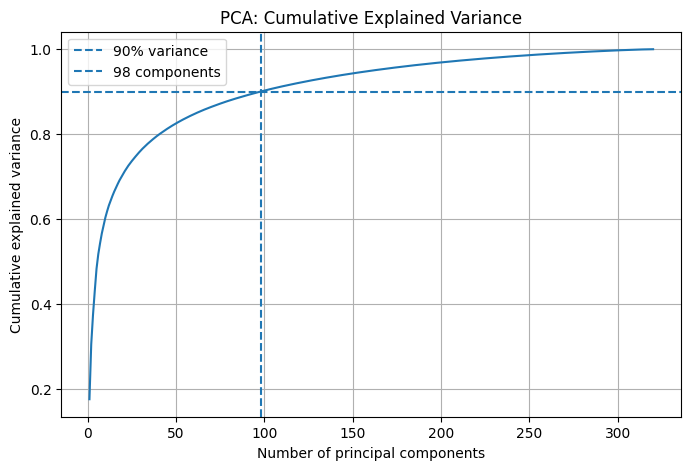

In [50]:
# Plot the cummulative variance

plt.figure(figsize=(8, 5))

plt.plot(
    np.arange(1, len(cum_var) + 1),
    cum_var
)

plt.axhline(y=0.90, linestyle="--", label="90% variance")
plt.axvline(x=n_comp, linestyle="--", label=f"{n_comp} components")

plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.show()

In [51]:
# Eigendecomposition finds eigenvectors and eigenvalues of covariance related matrix
# SVD(Singular value decomposition) directly decomposes the centered data matrix into orthogonal directions and sigular values

# Calculate PCA using SVD
# Apply SVD to the centered training images
u_mat, sing_vals, vt_mat = np.linalg.svd(train_centered, full_matrices=False)

# Principal directions in pixel space
svd_dirs = vt_mat.T

# Variance associated with each component
svd_var = sing_vals**2

# Explained and cumulative explained variance
svd_ratio = svd_var / np.sum(svd_var)
svd_cum = np.cumsum(svd_ratio)

print("U shape:", u_mat.shape)
print("Singular values shape:", sing_vals.shape)
print("Principal directions shape:", svd_dirs.shape)

U shape: (320, 320)
Singular values shape: (320,)
Principal directions shape: (10304, 320)


Eigenvalues from eigendecomposition:
[9.06150708e+08 6.62380815e+08 3.53743491e+08 2.89960577e+08
 2.69278582e+08 1.75971369e+08 1.31215354e+08 1.18963994e+08
 9.71120273e+07 9.37789320e+07]

Squared singular values from SVD:
[9.06150708e+08 6.62380815e+08 3.53743491e+08 2.89960577e+08
 2.69278582e+08 1.75971369e+08 1.31215354e+08 1.18963994e+08
 9.71120273e+07 9.37789320e+07]


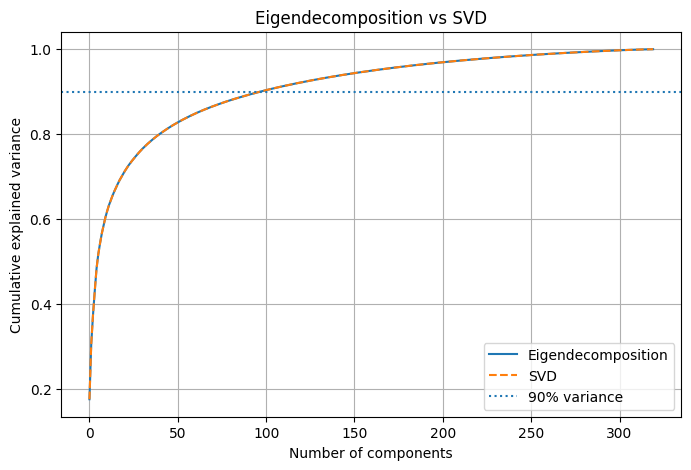

In [52]:
# Compare the first 10 eigenvalues with squared singular values
print("Eigenvalues from eigendecomposition:")
print(eig_vals[:10])

print("\nSquared singular values from SVD:")
print(sing_vals[:10]**2)

# Compare the cumulative explained variance curves
plt.figure(figsize=(8, 5))

plt.plot(cum_var, label="Eigendecomposition")
plt.plot(svd_cum, "--", label="SVD")
plt.axhline(0.90, linestyle=":", label="90% variance")

plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("Eigendecomposition vs SVD")
plt.legend()
plt.grid(True)
plt.show()

In [53]:
for idx in range(5):
    cos_sim = abs(np.dot(eig_faces[:, idx], svd_dirs[:, idx]))
    print(f"Component {idx + 1} similarity: {cos_sim:.6f}")

Component 1 similarity: 1.000000
Component 2 similarity: 1.000000
Component 3 similarity: 1.000000
Component 4 similarity: 1.000000
Component 5 similarity: 1.000000


In [54]:
# Keep the first k principal components
top_dirs = svd_dirs[:, :n_comp]

print("Number of components:", n_comp)
print("Selected components shape:", top_dirs.shape)

# Project the training faces into PCA space
# Compress each training image into k values
train_proj = train_centered @ top_dirs

print("Original training data:", train_pixels.shape)
print("Compressed training data:", train_proj.shape)


Number of components: 98
Selected components shape: (10304, 98)
Original training data: (320, 10304)
Compressed training data: (320, 98)


##### B.3 Project faces into PCA space, store the reduced representation, reconstruct sample faces, and compare reconstruction quality and storage with the original pixel representation.

Reconstructed data shape: (320, 10304)


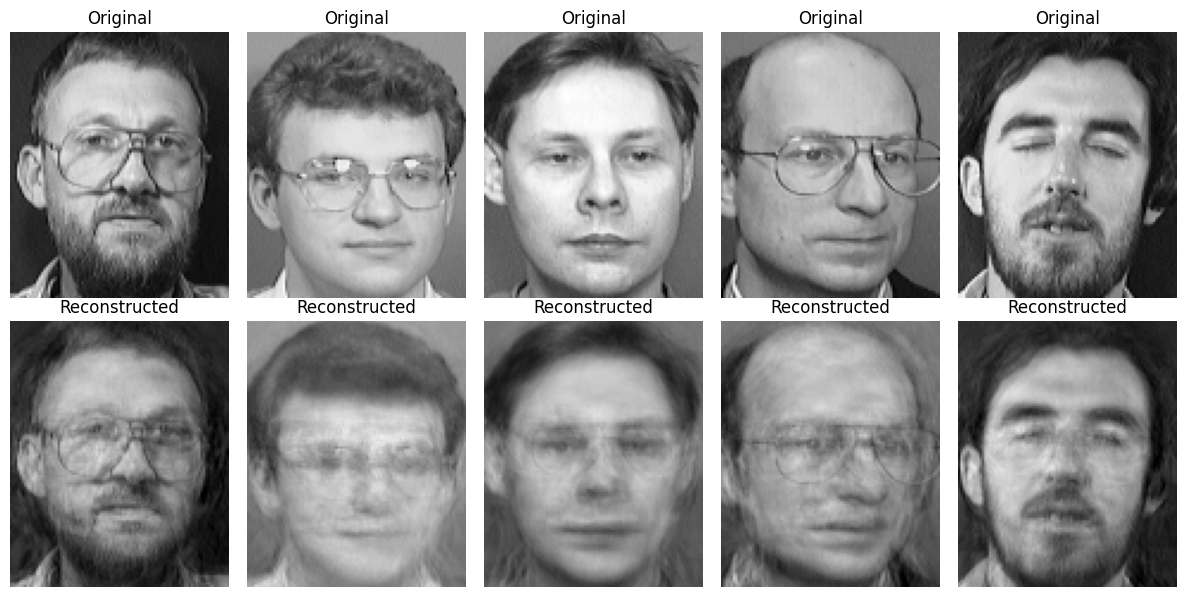

In [55]:
# To reconstruct the image we expand its PCA representation back into pixel space and add the mean face again
train_recon_pix = train_proj @ top_dirs.T + avg_face

print("Reconstructed data shape:", train_recon_pix.shape)

plt.figure(figsize=(12, 6))

for idx in range(5):
    # Original image
    plt.subplot(2, 5, idx + 1)
    plt.imshow(train_pixels[idx].reshape(face_imgs[0].shape), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, 5, idx + 6)
    plt.imshow(
        train_recon_pix[idx].reshape(face_imgs[0].shape),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [56]:
# Measure reconstructed error using MSE - it measures the avg squared difference betweeen original and reconstructed pixel values
train_recon_err = np.mean((train_pixels - train_recon_pix) ** 2)

print("Reconstruction MSE:", train_recon_err)

Reconstruction MSE: 154.67996532897942


Test images: (80, 10304)
Test images in PCA space: (80, 98)


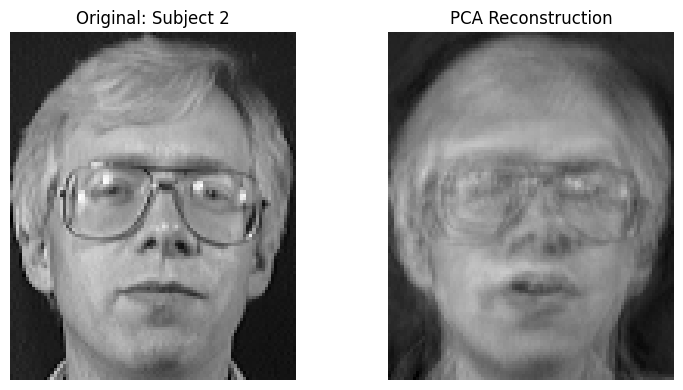

In [57]:
# Center the test images using the training mean face
test_centered = test_pixels - avg_face

# Project test images onto the selected principal components
test_proj = test_centered @ top_dirs

print("Test images:", test_pixels.shape)
print("Test images in PCA space:", test_proj.shape)

# Reconstruct the first test image
test_recon_img = test_proj[0] @ top_dirs.T + avg_face

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(test_pixels[0].reshape(face_imgs[0].shape), cmap="gray")
plt.title(f"Original: Subject {test_targets[0]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(
    test_recon_img.reshape(face_imgs[0].shape),
    cmap="gray",
    vmin=0,
    vmax=255
)
plt.title("PCA Reconstruction")
plt.axis("off")

plt.tight_layout()
plt.show()

In [58]:
test_recon_pix = test_proj @ top_dirs.T + avg_face

test_recon_err = np.mean((test_pixels - test_recon_pix) ** 2)

print("Test reconstruction MSE:", test_recon_err)

Test reconstruction MSE: 334.9898829101201


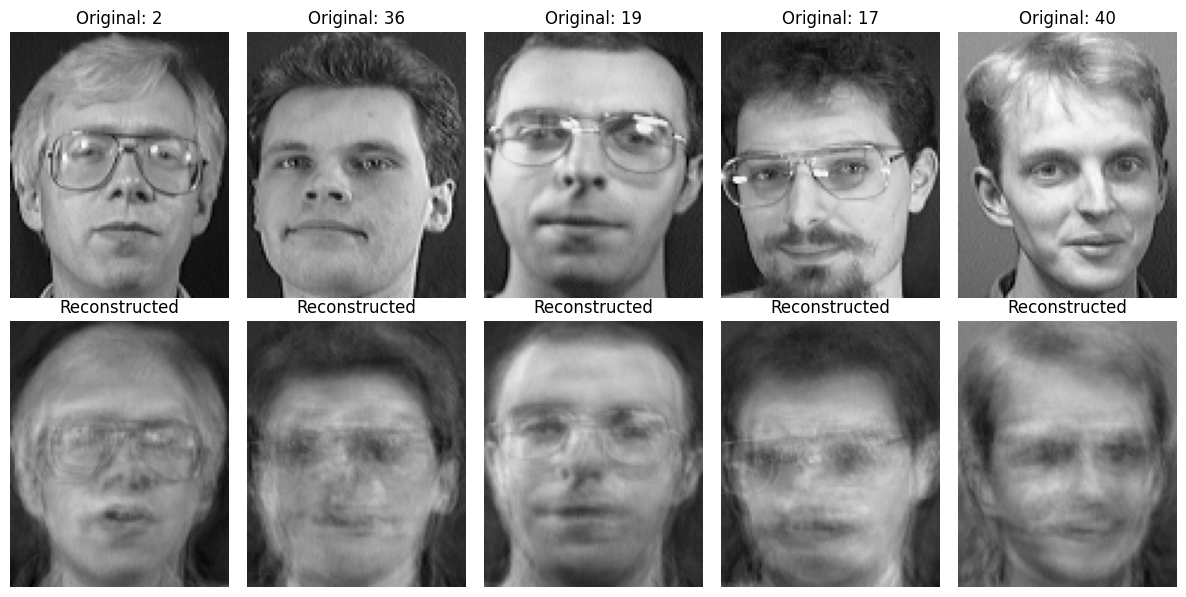

In [59]:
plt.figure(figsize=(12, 6))

for idx in range(5):
    recon_row = test_proj[idx] @ top_dirs.T + avg_face

    plt.subplot(2, 5, idx + 1)
    plt.imshow(test_pixels[idx].reshape(face_imgs[0].shape), cmap="gray")
    plt.title(f"Original: {test_targets[idx]}")
    plt.axis("off")

    plt.subplot(2, 5, idx + 6)
    plt.imshow(
        recon_row.reshape(face_imgs[0].shape),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [75]:
# Erros at different component count
for n_pc in [10, 25, 50, 100, 150, 200]:
    n_pc = min(n_pc, svd_dirs.shape[1])

    pc_subset = svd_dirs[:, :n_pc]

    train_reduced = train_centered @ pc_subset
    train_back = train_reduced @ pc_subset.T + avg_face

    test_reduced_pc = test_centered @ pc_subset
    test_back = test_reduced_pc @ pc_subset.T + avg_face

    train_err = np.mean((train_pixels - train_back) ** 2)
    test_recon_err = np.mean((test_pixels - test_back) ** 2)

    print(
        f"{n_pc:3d} components | "
        f"Train MSE: {train_err:.2f} | "
        f"Test MSE: {test_recon_err:.2f}"
    )

 10 components | Train MSE: 616.11 | Test MSE: 664.88
 25 components | Train MSE: 409.11 | Test MSE: 500.87
 50 components | Train MSE: 271.44 | Test MSE: 404.31
100 components | Train MSE: 151.40 | Test MSE: 333.40
150 components | Train MSE: 88.39 | Test MSE: 304.74
200 components | Train MSE: 48.25 | Test MSE: 284.94


#### Part C - Recongnition in PCA Space

##### C.1 For each test image, generate its PCA representation and identify the closest stored training face using a suitable distance measure such as Euclidean distance.

In [61]:
# Calculate distance from every test face to every training face
pca_dist = np.linalg.norm(
    test_proj[:, None, :] - train_proj[None, :, :],
    axis=2
)

# Find the closest training face for each test image
pca_nn_idx = np.argmin(pca_dist, axis=1)

# Predict the subject label
pca_pred = train_targets[pca_nn_idx]

# Calculate recognition accuracy
pca_acc = np.mean(pca_pred == test_targets)

print(f"Recognition accuracy: {pca_acc * 100:.2f}%")
print("Correct predictions:", np.sum(pca_pred == test_targets), "out of", len(test_targets))

Recognition accuracy: 96.25%
Correct predictions: 77 out of 80


##### C.2 Report recognition accuracy, inspect a few correct and incorrect matches, and compare recognition using raw pixels with recognition using the reduced PCA representation.

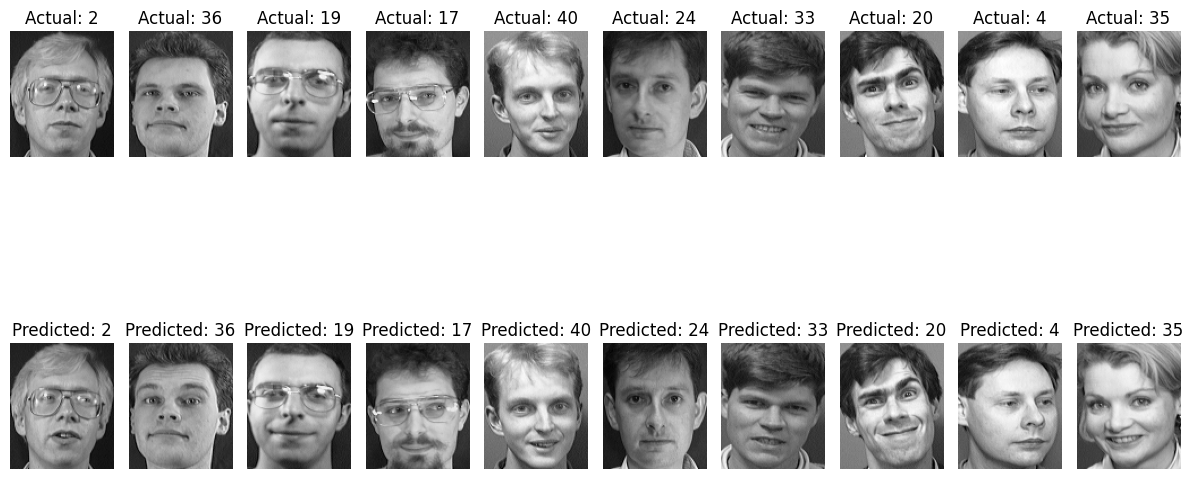

In [62]:
# Here is the visualization of some test faces alongside their nearest training matches. This will help us understand which faces the model recognizes correctly and where it makes mistakes.
plt.figure(figsize=(12, 8))

for idx in range(10):
    # Find the closest training face
    train_idx = pca_nn_idx[idx]

    # Show the test face
    plt.subplot(2, 10, idx + 1)
    plt.imshow(test_pixels[idx].reshape(face_imgs[0].shape), cmap="gray")
    plt.title(f"Actual: {test_targets[idx]}")
    plt.axis("off")

    # Show the closest training face
    plt.subplot(2, 10, idx + 11)
    plt.imshow(train_pixels[train_idx].reshape(face_imgs[0].shape), cmap="gray")
    plt.title(f"Predicted: {pca_pred[idx]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Number of incorrect predictions: 3


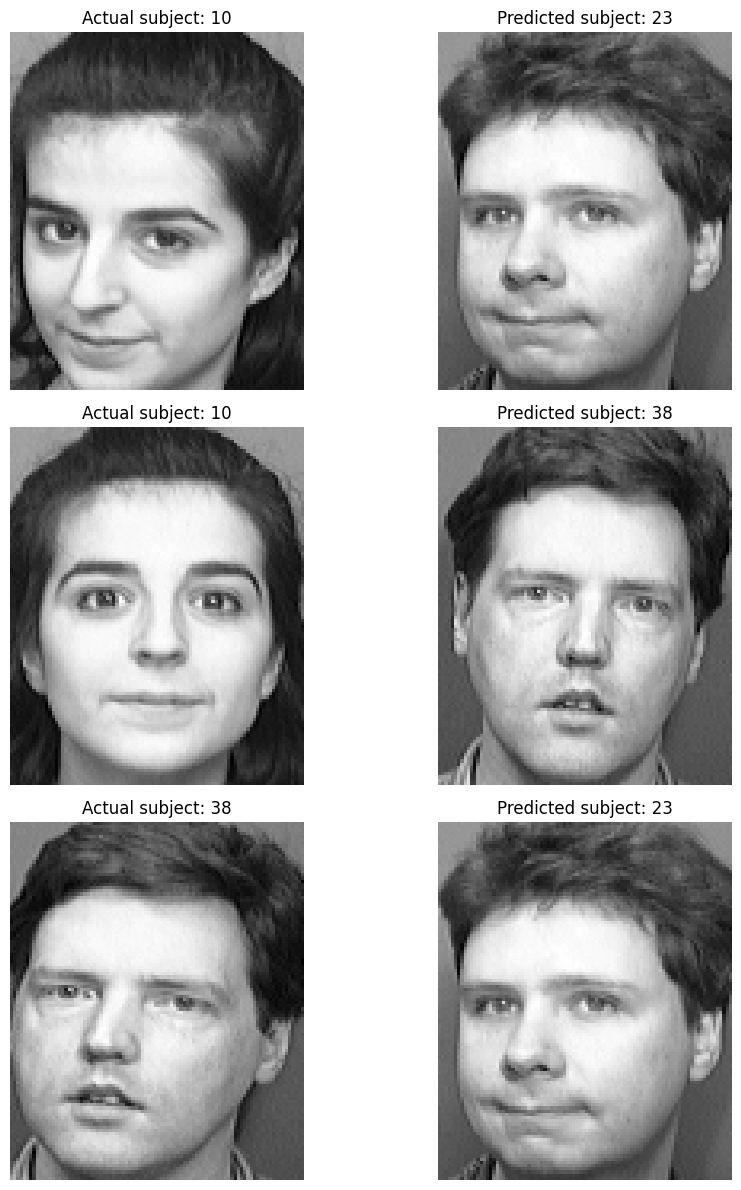

In [63]:
# Inspect the three incorrect predictions
# Find the positions where predicted labels differ from actual labels
miss_idx = np.where(pca_pred != test_targets)[0]

print("Number of incorrect predictions:", len(miss_idx))

# Display each incorrect prediction and its closest match
plt.figure(figsize=(10, 4 * len(miss_idx)))

for idx, test_idx in enumerate(miss_idx):
    train_idx = pca_nn_idx[test_idx]

    # Test face
    plt.subplot(len(miss_idx), 2, 2 * idx + 1)
    plt.imshow(test_pixels[test_idx].reshape(face_imgs[0].shape), cmap="gray")
    plt.title(f"Actual subject: {test_targets[test_idx]}")
    plt.axis("off")

    # Closest training face
    plt.subplot(len(miss_idx), 2, 2 * idx + 2)
    plt.imshow(train_pixels[train_idx].reshape(face_imgs[0].shape), cmap="gray")
    plt.title(f"Predicted subject: {pca_pred[test_idx]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [64]:
# Compare the raw pixels against PCA
# Calculate distances between raw test and training images
pix_dist = np.linalg.norm(
    test_pixels[:, None, :] - train_pixels[None, :, :],
    axis=2
)

# Find the closest training image
pix_nn_idx = np.argmin(pix_dist, axis=1)

# Predict subject labels
pix_pred = train_targets[pix_nn_idx]

# Calculate accuracy
pix_acc = np.mean(pix_pred == test_targets)

print(f"Raw pixel accuracy: {pix_acc * 100:.2f}%")
print(f"PCA accuracy: {pca_acc * 100:.2f}%")

Raw pixel accuracy: 96.25%
PCA accuracy: 96.25%


In [68]:
print("Raw training shape:", train_pixels.shape)
print("PCA training shape:", train_proj.shape)

print("Raw test shape:", test_pixels.shape)
print("PCA test shape:", test_proj.shape)

print("Training labels match:", len(train_targets) == len(train_proj))
print("Test labels match:", len(test_targets) == len(test_proj))

Raw training shape: (320, 10304)
PCA training shape: (320, 98)
Raw test shape: (80, 10304)
PCA test shape: (80, 98)
Training labels match: True
Test labels match: True


#### Part D - Traditional Machine Learning

##### D.1 Use the PCA features to train at least two traditional classifiers such as KNN, Logistic Regression, or SVM, and compare them with the similarity-based baseline.

In [69]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Train KNN
knn_clf = KNeighborsClassifier(n_neighbors=1)
knn_clf.fit(train_proj, train_targets)
knn_out = knn_clf.predict(test_proj)

# Train SVM
svm_clf = SVC(kernel="rbf")
svm_clf.fit(train_proj, train_targets)
svm_out = svm_clf.predict(test_proj)

# Compare accuracy
print(f"PCA nearest neighbor: {pca_acc * 100:.2f}%")
print(f"KNN accuracy: {accuracy_score(test_targets, knn_out) * 100:.2f}%")
print(f"SVM accuracy: {accuracy_score(test_targets, svm_out) * 100:.2f}%")

PCA nearest neighbor: 96.25%
KNN accuracy: 96.25%
SVM accuracy: 98.75%


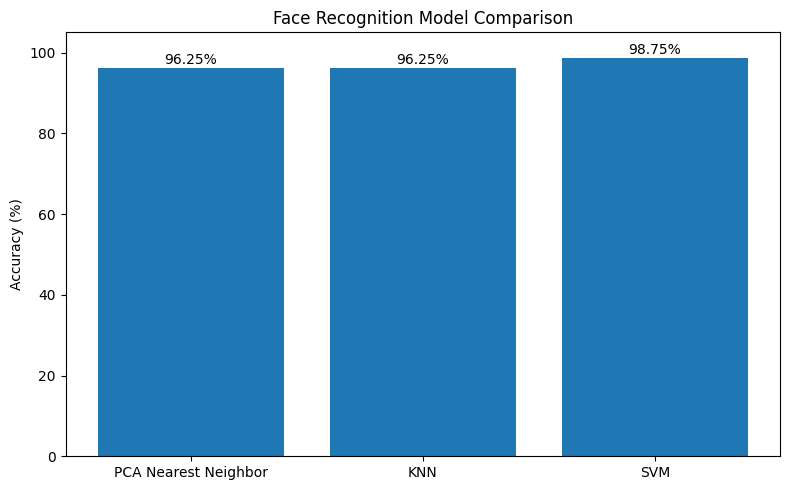

In [70]:
# Visualizing both models accuracy
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

clf_names = ["PCA Nearest Neighbor", "KNN", "SVM"]

acc_list = [
    pca_acc * 100,
    accuracy_score(test_targets, knn_out) * 100,
    accuracy_score(test_targets, svm_out) * 100
]

plt.figure(figsize=(8, 5))
bar_objs = plt.bar(clf_names, acc_list)

plt.ylabel("Accuracy (%)")
plt.title("Face Recognition Model Comparison")
plt.ylim(0, 105)

for bar_obj, acc_val in zip(bar_objs, acc_list):
    plt.text(
        bar_obj.get_x() + bar_obj.get_width() / 2,
        acc_val + 1,
        f"{acc_val:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

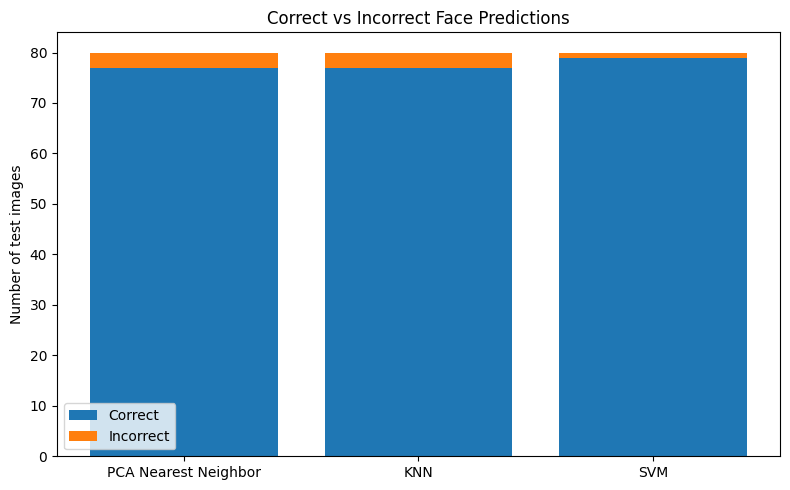

In [71]:
# Correct vs Incorrect predictions
n_correct = [
    sum(pca_pred == test_targets),
    sum(knn_out == test_targets),
    sum(svm_out == test_targets)
]

n_wrong = [
    len(test_targets) - n_correct[0],
    len(test_targets) - n_correct[1],
    len(test_targets) - n_correct[2]
]

plt.figure(figsize=(8, 5))

plt.bar(clf_names, n_correct, label="Correct")
plt.bar(clf_names, n_wrong, bottom=n_correct, label="Incorrect")

plt.ylabel("Number of test images")
plt.title("Correct vs Incorrect Face Predictions")
plt.legend()
plt.tight_layout()
plt.show()

##### D.2 Experiment with the number of retained components and suitable model settings to improve recognition while keeping the representation compact.

In [72]:

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

pc_grid = [10, 25, 50, 75, 98, 150, 200]
grid_results = []

for n_comp in pc_grid:
    # Keep the first k principal components
    pcs_k = svd_dirs[:, :n_comp]

    # Project training and test faces into PCA space
    train_feat = train_centered @ pcs_k
    test_feat = test_centered @ pcs_k

    # Experiment with KNN settings
    for nn_k in [1, 3, 5]:
        clf = KNeighborsClassifier(n_neighbors=nn_k)
        clf.fit(train_feat, train_targets)
        grid_pred = clf.predict(test_feat)

        grid_results.append({
            "Components": n_comp,
            "Model": f"KNN (k={nn_k})",
            "Accuracy": accuracy_score(test_targets, grid_pred) * 100
        })

    # Experiment with SVM regularization settings
    for reg_c in [0.1, 1, 10, 100]:
        clf = SVC(kernel="rbf", C=reg_c)
        clf.fit(train_feat, train_targets)
        grid_pred = clf.predict(test_feat)

        grid_results.append({
            "Components": n_comp,
            "Model": f"SVM (C={reg_c})",
            "Accuracy": accuracy_score(test_targets, grid_pred) * 100
        })

# Display the best-performing combinations
grid_results = sorted(
    grid_results,
    key=lambda res_row: res_row["Accuracy"],
    reverse=True
)

for res_row in grid_results[:15]:
    print(
        f"Components: {res_row['Components']:3} | "
        f"{res_row['Model']:15} | "
        f"Accuracy: {res_row['Accuracy']:.2f}%"
    )


Components:  10 | SVM (C=10)      | Accuracy: 98.75%
Components:  10 | SVM (C=100)     | Accuracy: 98.75%
Components:  25 | SVM (C=10)      | Accuracy: 98.75%
Components:  25 | SVM (C=100)     | Accuracy: 98.75%
Components:  50 | KNN (k=1)       | Accuracy: 98.75%
Components:  50 | SVM (C=10)      | Accuracy: 98.75%
Components:  50 | SVM (C=100)     | Accuracy: 98.75%
Components:  75 | SVM (C=1)       | Accuracy: 98.75%
Components:  75 | SVM (C=10)      | Accuracy: 98.75%
Components:  75 | SVM (C=100)     | Accuracy: 98.75%
Components:  98 | SVM (C=1)       | Accuracy: 98.75%
Components:  98 | SVM (C=10)      | Accuracy: 98.75%
Components:  98 | SVM (C=100)     | Accuracy: 98.75%
Components: 150 | SVM (C=10)      | Accuracy: 98.75%
Components: 150 | SVM (C=100)     | Accuracy: 98.75%


In [73]:
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

X_train = train_pixels.astype(np.float64)      # float, avoids uint8 wrap-around
pc_grid = [10, 25, 50, 75, 98, 150]

models = {f"KNN (k={k})": (lambda k=k: KNeighborsClassifier(n_neighbors=k)) for k in [1, 3, 5]}
models.update({f"SVM (C={c})": (lambda c=c: SVC(kernel="rbf", C=c)) for c in [0.1, 1, 10, 100]})

skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)  # 8 imgs/subject -> 2 per fold
cv_scores = {}

for tr_idx, va_idx in skf.split(X_train, train_targets):
    mu = X_train[tr_idx].mean(axis=0)
    Xc = X_train[tr_idx] - mu
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)   # PCA fitted on this fold only

    for k in pc_grid:
        W = Vt[:k].T
        f_tr, f_va = Xc @ W, (X_train[va_idx] - mu) @ W
        for name, make in models.items():
            acc = make().fit(f_tr, train_targets[tr_idx]).score(f_va, train_targets[va_idx])
            cv_scores.setdefault((k, name), []).append(acc)

cv_table = sorted(((np.mean(v), np.std(v), k, n) for (k, n), v in cv_scores.items()), reverse=True)
for m, s, k, n in cv_table[:10]:
    print(f"{k:3d} comps | {n:12} | CV acc {m*100:.2f}% ± {s*100:.2f}")

best_cv_acc, _, best_k, best_name = cv_table[0]

# Refit on the full training set, then touch the test set once
mu = X_train.mean(axis=0)
Xc = X_train - mu
_, _, Vt = np.linalg.svd(Xc, full_matrices=False)
W = Vt[:best_k].T
final = models[best_name]().fit(Xc @ W, train_targets)
test_acc = final.score((test_pixels.astype(np.float64) - mu) @ W, test_targets)
print(f"\nChosen: {best_name}, {best_k} comps | test accuracy (used once): {test_acc*100:.2f}%")

 75 comps | SVM (C=100)  | CV acc 98.12% ± 0.63
 75 comps | SVM (C=10)   | CV acc 98.12% ± 0.63
 50 comps | SVM (C=100)  | CV acc 98.12% ± 0.63
 50 comps | SVM (C=10)   | CV acc 98.12% ± 0.63
150 comps | SVM (C=100)  | CV acc 97.81% ± 0.54
150 comps | SVM (C=10)   | CV acc 97.81% ± 0.54
 98 comps | SVM (C=100)  | CV acc 97.81% ± 0.54
 98 comps | SVM (C=10)   | CV acc 97.81% ± 0.54
 25 comps | SVM (C=100)  | CV acc 96.56% ± 2.23
 25 comps | SVM (C=10)   | CV acc 96.56% ± 2.23

Chosen: SVM (C=100), 75 comps | test accuracy (used once): 98.75%


##### D.3 Selected configuration

Settings were chosen by 4-fold stratified cross-validation on the **training set only**, with PCA refitted inside each fold so that no validation face influenced the eigenfaces. The best cross-validated accuracy was **98.12% (± 0.63)**, reached by an RBF-kernel SVM with 50 to 75 retained components. The selected configuration is an **SVM (RBF, C=100) on 75 PCA components**; C=10 and C=100 tie, and 50 and 75 components tie on CV accuracy.

Refitted on the full training set and evaluated once on the held-out test set, it achieved **98.75%** (79 of 80 images correct). The representation shrinks from 10,304 pixel values to 75 features per image, a reduction of about 99.3%.

Earlier, the same grid was searched using test accuracy directly. That result is kept above for reference, but only the cross-validated choice is used for the final conclusion, because selecting on the test set would give an optimistic estimate.

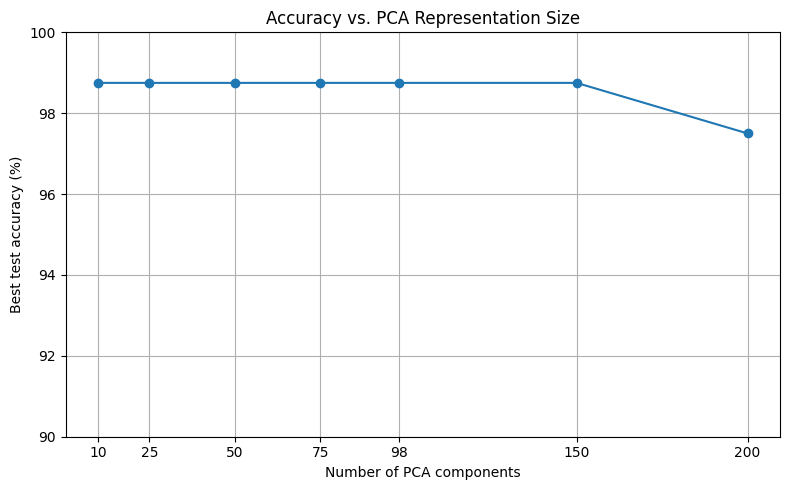

In [74]:

import matplotlib.pyplot as plt

# Best accuracy for each component count
best_per_pc = {}

for res_row in grid_results:
    n_comp = res_row["Components"]
    best_score = res_row["Accuracy"]

    if n_comp not in best_per_pc or best_score > best_per_pc[n_comp]:
        best_per_pc[n_comp] = best_score

pc_grid = sorted(best_per_pc)
best_acc_list = [
    best_per_pc[n_comp] for n_comp in pc_grid
]

plt.figure(figsize=(8, 5))
plt.plot(
    pc_grid,
    best_acc_list,
    marker="o"
)

plt.xlabel("Number of PCA components")
plt.ylabel("Best test accuracy (%)")
plt.title("Accuracy vs. PCA Representation Size")
plt.xticks(pc_grid)
plt.ylim(90, 100)
plt.grid(True)
plt.tight_layout()
plt.show()
